# Exploratory Data Analysis Notebook

**Outstanding Questions**
- maybe need a way to filter out or map product names? 
- decide what preprocessing to apply to the full-length `Text`

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import re
import numpy as np

## 0. Load in CSV file

In [ ]:
# File too large to commit through GitHub so using compressed version here
df = pd.read_csv('Reviews.csv.xz')
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [3]:
# add helpfulness ratio column
df['helpful_ratio'] = df['HelpfulnessNumerator'] / df['HelpfulnessDenominator']

## 1. Explore row and column data

**Data Dictionary**

| Column Name | Description |
|---|---|
| Id | Row ID |
| ProductId | Unique identifier for the product |
| UserId | Unique identifier for the user |
| ProfileName | Profile name of the user |
| HelpfulnessNumerator | Number of users who found the review helpful |
| HelpfulnessDenominator | Number of users who rated the review's helpfulness (helpful or not) |
| Score | Rating between 1 and 5 |
| Time | Timestamp for the review |
| Summary | Brief summary of the review |
| Text | Text of the review |

In [4]:
# print out one row for further inspection
print(df.iloc[0])
print(df.iloc[0]["Text"])

Id                                                                        1
ProductId                                                        B001E4KFG0
UserId                                                       A3SGXH7AUHU8GW
ProfileName                                                      delmartian
HelpfulnessNumerator                                                      1
HelpfulnessDenominator                                                    1
Score                                                                     5
Time                                                             1303862400
Summary                                               Good Quality Dog Food
Text                      I have bought several of the Vitality canned d...
helpful_ratio                                                           1.0
Name: 0, dtype: object
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a s

In [5]:
# number samples & unique values 
print(f"Columns: {df.columns}")
print(f"Shape: {df.shape}")

# distribution by column grouppings
for col in df.columns:
    print(f"\n{col}: {df[col].nunique()} unique values")
    # print(df[col].value_counts(dropna=False).head(10))


Columns: Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text',
       'helpful_ratio'],
      dtype='object')
Shape: (568454, 11)

Id: 568454 unique values

ProductId: 74258 unique values

UserId: 256059 unique values

ProfileName: 218415 unique values

HelpfulnessNumerator: 231 unique values

HelpfulnessDenominator: 234 unique values

Score: 5 unique values

Time: 3168 unique values

Summary: 295742 unique values

Text: 393579 unique values

helpful_ratio: 951 unique values


In [6]:
# Time range of available data 
min_date = pd.to_datetime(df["Time"].min(), unit="s")
max_date = pd.to_datetime(df["Time"].max(), unit="s")
print(min_date, max_date)

1999-10-08 00:00:00 2012-10-26 00:00:00


Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64
Score
1    0.092
2    0.052
3    0.075
4    0.142
5    0.639
Name: proportion, dtype: float64


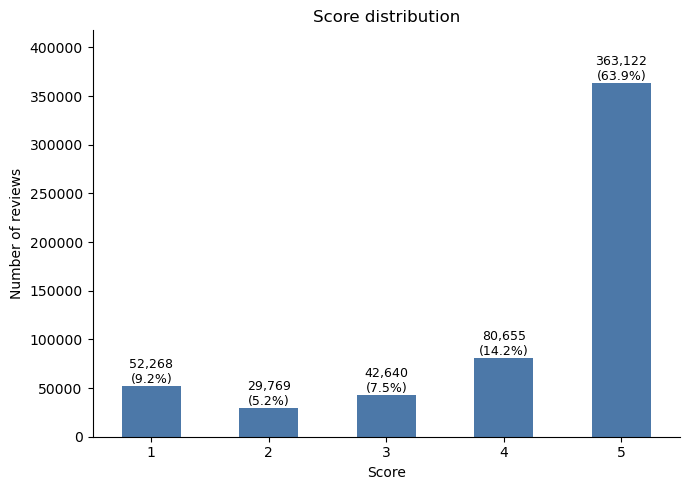

In [7]:
# -- Distribution for Categorical variables 
# Score is truly categorical (1-5): full distribution, as counts and percentages
print(df['Score'].value_counts().sort_index())
print(df['Score'].value_counts(normalize=True).sort_index().round(3))

counts = df['Score'].value_counts().sort_index()
pcts = df['Score'].value_counts(normalize=True).sort_index() * 100

ax = counts.plot(kind='bar', color='#4C78A8', figsize=(7, 5), rot=0)
for bar, pct in zip(ax.patches, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():,.0f}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9)

ax.set_title('Score distribution')
ax.set_xlabel('Score')
ax.set_ylabel('Number of reviews')
ax.set_ylim(0, counts.max() * 1.15)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [8]:
# Helpfulness columns are counts: bin or look at the top values
print(df['HelpfulnessNumerator'].describe()) # Number of users who found the review helpful
print(df['HelpfulnessDenominator'].describe()) # Number of users who indicated whether they found the review helpful or not

count    568454.000000
mean          1.743817
std           7.636513
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max         866.000000
Name: HelpfulnessNumerator, dtype: float64
count    568454.00000
mean          2.22881
std           8.28974
min           0.00000
25%           0.00000
50%           1.00000
75%           2.00000
max         923.00000
Name: HelpfulnessDenominator, dtype: float64


## 2. Product-Based Exploration

In [9]:
# most reviewed product?
review_counts = df['ProductId'].value_counts()
print(review_counts.head(10))
print("Most reviewed:", review_counts.index[0], "with", review_counts.iloc[0], "reviews")

# --- sort dataframe by product with the most reviews
df['product_review_count'] = df.groupby('ProductId')['ProductId'].transform('count')
df_sorted = df.sort_values('product_review_count', ascending=False)   # assign it, or the sort is thrown away

# per-product stats
product_stats = (df.groupby('ProductId')['Score']
                   .agg(avg_score='mean', n_reviews='count')
                   .reset_index())

# --- highest / lowest scored AND well reviewed
MIN_REVIEWS = 50   # adjust: check product_stats['n_reviews'].describe() for what's typical
qualified = product_stats[product_stats['n_reviews'] >= MIN_REVIEWS]

print(f"Highest scored (min {MIN_REVIEWS} reviews):")
display(qualified.sort_values(['avg_score', 'n_reviews'], ascending=[False, False]).head(5))

print(f"Lowest scored (min {MIN_REVIEWS} reviews):")
display(qualified.sort_values(['avg_score', 'n_reviews'], ascending=[True, False]).head(5))

# --- alternative: start from the most reviewed products, then rank by score
top_reviewed = product_stats.nlargest(50, 'n_reviews')

print("Among the 50 most reviewed products, highest scored:")
display(top_reviewed.sort_values('avg_score', ascending=False).head(5))

print("Among the 50 most reviewed products, lowest scored:")
display(top_reviewed.sort_values('avg_score').head(5))

ProductId
B007JFMH8M    913
B0026RQTGE    632
B002QWHJOU    632
B002QWP89S    632
B002QWP8H0    632
B003B3OOPA    623
B001EO5Q64    567
B000VK8AVK    564
B0026KNQSA    564
B007M83302    564
Name: count, dtype: int64
Most reviewed: B007JFMH8M with 913 reviews
Highest scored (min 50 reviews):


,ProductId,avg_score,n_reviews
8253,B000ED9L9E,4.973451,113
17287,B000O5DI1E,4.906542,107
28071,B001E6GFKI,4.887500,80
16945,B000NMJWZO,4.881919,542
53187,B0044MTGHI,4.880000,50


Lowest scored (min 50 reviews):


,ProductId,avg_score,n_reviews
69165,B006N3I69A,1.343511,131
57259,B004H3N2LU,1.373494,83
21233,B000X1Q1G8,1.695652,184
17913,B000PGE032,2.000000,55
64059,B005BHIESC,2.439024,82


Among the 50 most reviewed products, highest scored:


,ProductId,avg_score,n_reviews
16945,B000NMJWZO,4.881919,542
28624,B001EO5Q64,4.746032,567
46205,B003B3OOPA,4.739968,623
42257,B002QWHJOU,4.588608,632
42263,B002QWP89S,4.588608,632


Among the 50 most reviewed products, lowest scored:


,ProductId,avg_score,n_reviews
69118,B006MONQMC,3.380855,491
14399,B000KV7ZGQ,3.411871,556
14398,B000KV61FC,3.411871,556
40885,B002IEZJMA,3.601643,487
60393,B004SRH2B6,3.671053,456


In [10]:
# View a random sampling of the reviews from the highest and lowest scores 
import textwrap

def show_reviews(data, n=5, seed=None, width=100):
    sample = data.sample(min(n, len(data)), random_state=seed)
    for _, row in sample.iterrows():
        text = re.sub(r'<[^>]+>', ' ', str(row['Text']))   # strip HTML like <br />
        print(f"[{row['Score']} stars | {row['HelpfulnessNumerator']}/{row['HelpfulnessDenominator']} helpful | {row['ProductId']}]")
        print(f"Summary: {row['Summary']}")
        print(textwrap.fill(text, width=width))
        print("-" * width)

print("=== HIGHEST SCORED (5 stars) ===")
show_reviews(df[df['Score'] == 5], n=5)

print("\n=== LOWEST SCORED (1 star) ===")
show_reviews(df[df['Score'] == 1], n=5)

=== HIGHEST SCORED (5 stars) ===
[5 stars | 1/1 helpful | B000E4AKQ6]
Summary: Great Tea
India Spice is a great tea if you like your herbal tea with a little kick.  It's strong, flavorful,
and aromatic.  Also, the little fortunes are a nice little twist.
----------------------------------------------------------------------------------------------------
[5 stars | 1/1 helpful | B000V17MLS]
Summary: excellent curry paste
I purchased this curry paste to make Butter Chicken. There are no Indian food markets in the rural
area in which I live, and I was delighted at the quality and quantity which I received. I will
definitely purchase from this seller again. Thanks!  Melanie
----------------------------------------------------------------------------------------------------
[5 stars | 0/0 helpful | B003AP7C1M]
Summary: Great Pump, High Energy
I bought this product in bulk after trying a single bottle at my local 24 Hour Fitness.  The cost
per single bottle at my gym was nearly 4 times that 

In [11]:
# Wider low group (1-2 stars)
print("\n=== WIDER LOWEST SCORED (1-2 star) ===")
show_reviews(df[df['Score'] <= 2], n=5)

print("\n=== HELPFUL REVIEWS (1 star) ===")
# Only reviews other readers found helpful (more representative of what people agree on)
show_reviews(df[(df['Score'] == 1) & (df['HelpfulnessDenominator'] >= 5) & (df['helpful_ratio'] >= 0.8)], n=5)

print("\n=== ABOVE MIN NUMBER OF REVIEWS THRESHOLD ===")
# Reviews from the highest and lowest scored products (uses `qualified` from the product step)
top_ids = qualified.nlargest(5, 'avg_score')['ProductId']
bottom_ids = qualified.nsmallest(5, 'avg_score')['ProductId']
show_reviews(df[df['ProductId'].isin(top_ids)], n=5)
show_reviews(df[df['ProductId'].isin(bottom_ids)], n=5)


print("\n=== LONGER REVIEWS (1 star) ===")
# Short vs. long reviews
lengths = df['Text'].str.split().str.len()
show_reviews(df[(df['Score'] == 1) & (lengths > 150)], n=3)


=== WIDER LOWEST SCORED (1-2 star) ===
[1 stars | 3/6 helpful | B005K4Q4LK]
Summary: If you are health conscious, skip this product
I purchased this product and did not realize, until reading the ingredient list on the side of the
box, that it contained hydrogenated oils. I was unable to return the k cups due to amazon policy so
I had to throw the items in the trash.
----------------------------------------------------------------------------------------------------
[1 stars | 0/0 helpful | B005K4Q1VI]
Summary: Ugh so not what I was expecting >.&lt;
So if you are a person who likes swiss miss / hot cocoa packets or hot cocoa from a gas station SO
DO NOT GET THIS PRODUCT!  I can not taste any chocolate flavor in it whatsoever.  It just tastes
like heated sugar water and nasty sugar water at that.  This product has a strong fake sugar taste
and I am perfectly OK with diet sodas and other fake sugar products.  There is something about this
I just can not put a finger on it but it made my

In [12]:
# Some of the built-urls have products that were delisted :(
top = review_counts.head(10).reset_index()
top.columns = ['ProductId', 'n_reviews']
top['url'] = 'https://www.amazon.com/dp/' + top['ProductId']
print(top.to_string())

    ProductId  n_reviews                                   url
0  B007JFMH8M        913  https://www.amazon.com/dp/B007JFMH8M
1  B0026RQTGE        632  https://www.amazon.com/dp/B0026RQTGE
2  B002QWHJOU        632  https://www.amazon.com/dp/B002QWHJOU
3  B002QWP89S        632  https://www.amazon.com/dp/B002QWP89S
4  B002QWP8H0        632  https://www.amazon.com/dp/B002QWP8H0
5  B003B3OOPA        623  https://www.amazon.com/dp/B003B3OOPA
6  B001EO5Q64        567  https://www.amazon.com/dp/B001EO5Q64
7  B000VK8AVK        564  https://www.amazon.com/dp/B000VK8AVK
8  B0026KNQSA        564  https://www.amazon.com/dp/B0026KNQSA
9  B007M83302        564  https://www.amazon.com/dp/B007M83302


82037 363122 -> 20000 sampled from each


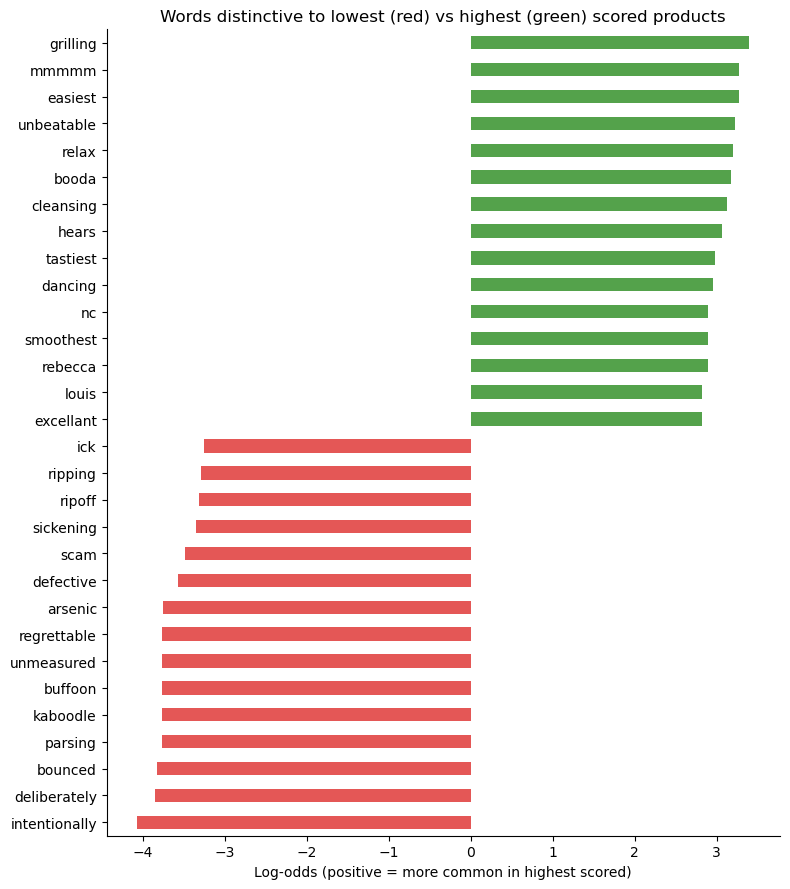

In [13]:
# -- make word clouds or a similar visualization on the "Text" column
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# SETUP
# --- applied filtering here! 
def clean(s):
    return re.sub(r'<[^>]+>', ' ', s).lower()

# --- Open to playing around with these thresholds
low_reviews = df[df['Score'] <= 2]
high_reviews = df[df['Score'] == 5]

# Balance the groups: 5-star reviews usually far outnumber 1-2 star ones
n = min(len(low_reviews), len(high_reviews), 20000)   # cap keeps it fast

# Apply random sampling 
low_text = low_reviews['Text'].astype(str).sample(n, random_state=42).map(clean)
high_text = high_reviews['Text'].astype(str).sample(n, random_state=42).map(clean)

print(len(low_reviews), len(high_reviews), "->", n, "sampled from each")

# Top DISTINCT words
cv = CountVectorizer(stop_words='english', min_df=10)
X = cv.fit_transform(pd.concat([low_text, high_text]))
labels = np.array([0] * len(low_text) + [1] * len(high_text))

low_c = np.asarray(X[labels == 0].sum(axis=0)).ravel() + 1    # +1 smoothing
high_c = np.asarray(X[labels == 1].sum(axis=0)).ravel() + 1
log_odds = np.log(high_c / high_c.sum()) - np.log(low_c / low_c.sum())

s = pd.Series(log_odds, index=cv.get_feature_names_out()).sort_values()
top = pd.concat([s.head(15), s.tail(15)])

ax = top.plot(kind='barh', figsize=(8, 9), color=['#E45756'] * 15 + ['#54A24B'] * 15)
ax.set_title('Words distinctive to lowest (red) vs highest (green) scored products')
ax.set_xlabel('Log-odds (positive = more common in highest scored)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


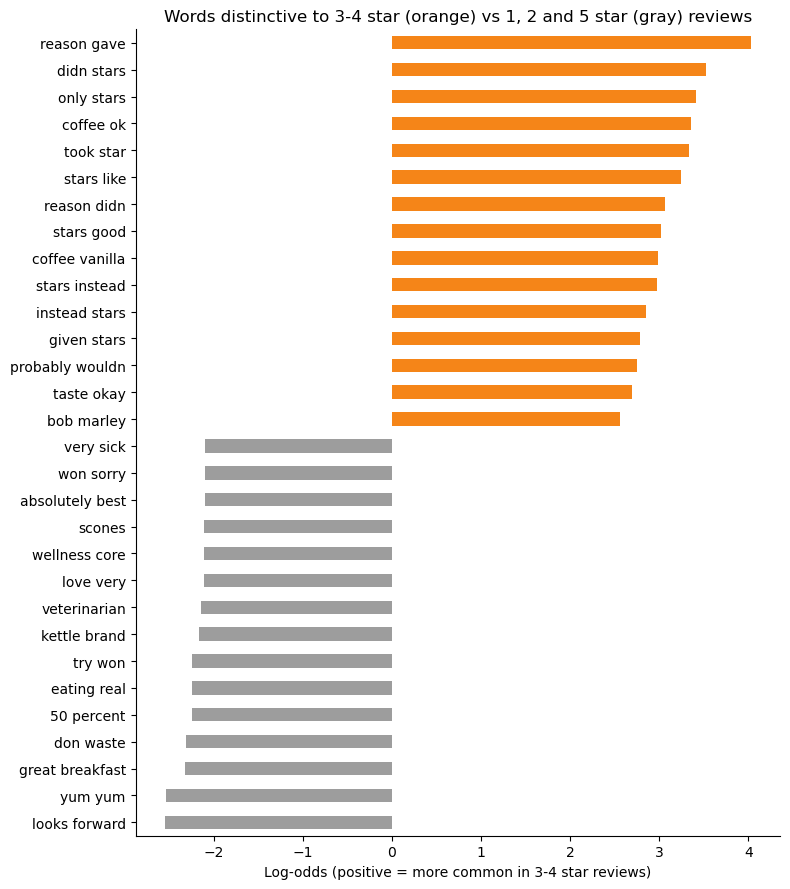

In [14]:
# Compare against middle-of-the-road reviews 
mid_reviews = df[df['Score'].isin([3, 4])]
other_reviews = df[~df['Score'].isin([3, 4])]

n = min(len(mid_reviews), len(other_reviews), 20000)
mid_text = mid_reviews['Text'].astype(str).sample(n, random_state=42).map(clean)
other_text = other_reviews['Text'].astype(str).sample(n, random_state=42).map(clean)

# Keep hedging/contrast words that the default stop list removes
keep = {'not', 'but', 'however', 'no', 'too', 'very', 'although', 'though', 'only', 'bit'}
stops = list(ENGLISH_STOP_WORDS - keep)

cv = CountVectorizer(stop_words=stops, ngram_range=(1, 2), min_df=20)
X = cv.fit_transform(pd.concat([mid_text, other_text]))
labels = np.array([1] * len(mid_text) + [0] * len(other_text))

mid_c = np.asarray(X[labels == 1].sum(axis=0)).ravel() + 1
other_c = np.asarray(X[labels == 0].sum(axis=0)).ravel() + 1
log_odds = np.log(mid_c / mid_c.sum()) - np.log(other_c / other_c.sum())

s = pd.Series(log_odds, index=cv.get_feature_names_out()).sort_values()
top = pd.concat([s.head(15), s.tail(15)])

ax = top.plot(kind='barh', figsize=(8, 9), color=['#9D9D9D'] * 15 + ['#F58518'] * 15)
ax.set_title('Words distinctive to 3-4 star (orange) vs 1, 2 and 5 star (gray) reviews')
ax.set_xlabel('Log-odds (positive = more common in 3-4 star reviews)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

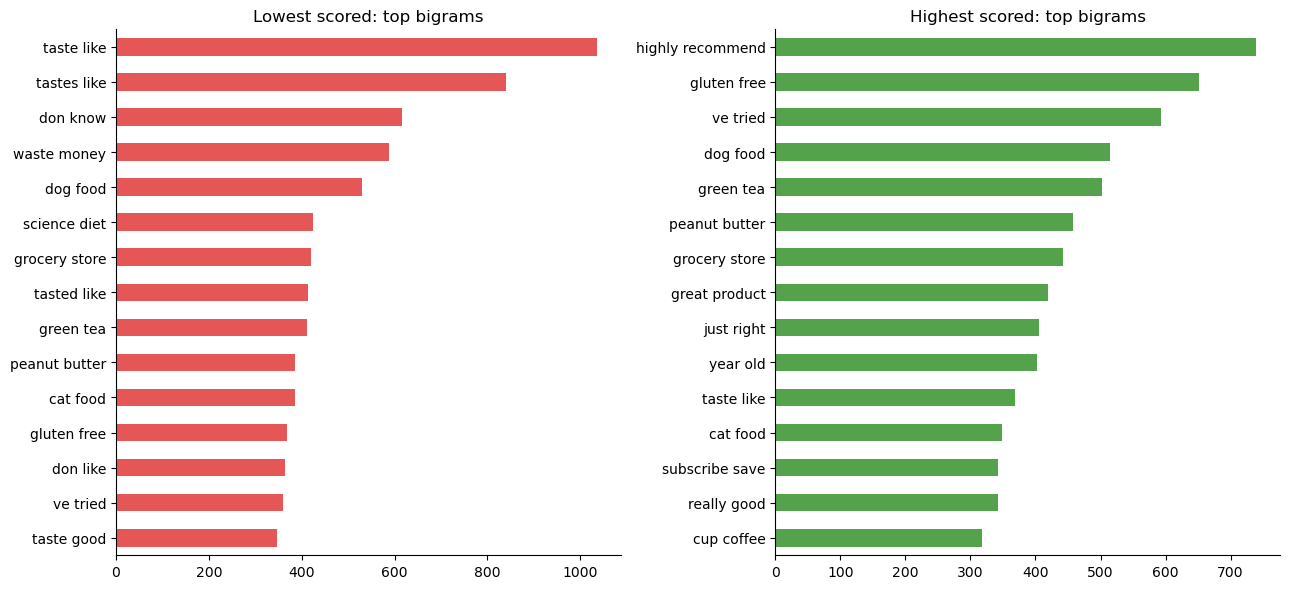

In [15]:
def top_terms(texts, n=15, ngram=(2, 2)):   # use (1, 1) for single words
    cv = CountVectorizer(stop_words='english', ngram_range=ngram, min_df=5)
    X = cv.fit_transform(texts)
    counts = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return counts.nlargest(n).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_terms(low_text).plot(kind='barh', ax=axes[0], color='#E45756', title='Lowest scored: top bigrams')
top_terms(high_text).plot(kind='barh', ax=axes[1], color='#54A24B', title='Highest scored: top bigrams')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

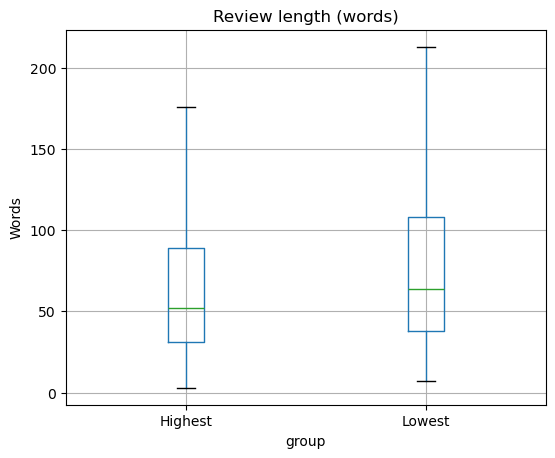

In [16]:
# Review Text Characteristics (Review Length)
lengths = pd.DataFrame({
    'group': ['Lowest'] * len(low_text) + ['Highest'] * len(high_text),
    'words': pd.concat([low_text, high_text]).str.split().str.len().values,
})
lengths.boxplot(column='words', by='group', showfliers=False, figsize=(6, 5))
plt.suptitle('')
plt.title('Review length (words)')
plt.ylabel('Words')
plt.show()

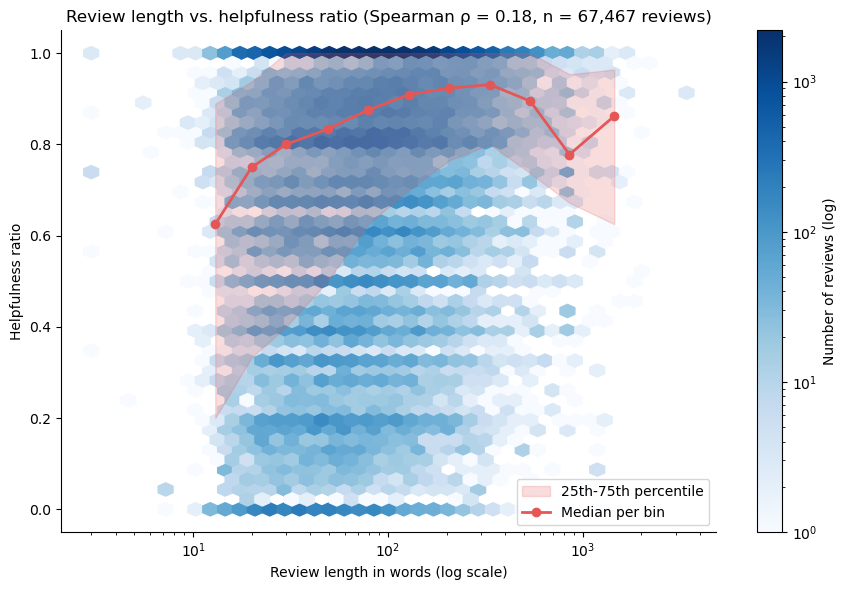

In [17]:
# Compare length of review against helpfulness of the review
# --- Can experiement with these thresholds
MIN_VOTES = 5           # a review's ratio only counts if it got at least this many votes

rev = df[df['HelpfulnessDenominator'] >= MIN_VOTES].copy()
rev['n_words'] = (rev['Text'].astype(str)
                     .str.replace(r'<[^>]+>', ' ', regex=True)   # strip HTML like <br />
                     .str.split().str.len())
rev = rev[rev['n_words'] > 0]

rho = rev[['n_words', 'helpful_ratio']].corr(method='spearman').iloc[0, 1]

fig, ax = plt.subplots(figsize=(9, 6))

# Density of reviews
hb = ax.hexbin(rev['n_words'], rev['helpful_ratio'],
               xscale='log', gridsize=40, mincnt=1, cmap='Blues', bins='log')
plt.colorbar(hb, label='Number of reviews (log)')

# Trend: median per log-spaced length bin, with a 25th-75th percentile band
bins = np.unique(np.logspace(np.log10(rev['n_words'].min()),
                             np.log10(rev['n_words'].max()), 15).round().astype(int))
rev['bin'] = pd.cut(rev['n_words'], bins=bins, include_lowest=True)
trend = rev.groupby('bin', observed=True).agg(
    x=('n_words', 'median'),
    y=('helpful_ratio', 'median'),
    q25=('helpful_ratio', lambda s: s.quantile(0.25)),
    q75=('helpful_ratio', lambda s: s.quantile(0.75)),
    reviews=('helpful_ratio', 'count'),
)
trend = trend[trend['reviews'] >= 30]   # drop sparse bins

ax.fill_between(trend['x'], trend['q25'], trend['q75'], color='#E45756', alpha=0.2, label='25th-75th percentile')
ax.plot(trend['x'], trend['y'], color='#E45756', marker='o', linewidth=2, label='Median per bin')

ax.set_xscale('log')
ax.set_xlabel('Review length in words (log scale)')
ax.set_ylabel('Helpfulness ratio')
ax.set_title(f'Review length vs. helpfulness ratio (Spearman ρ = {rho:.2f}, n = {len(rev):,} reviews)')
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 3. User-Based Exploration

In [18]:
# any mega reviewers and what are their averages scores and helpfulness ratings? 
# --- do they tend to have the most helpful reviews? 
# helpfulness ratio per review (undefined when nobody voted)
df['helpful_ratio'] = df['HelpfulnessNumerator'] / df['HelpfulnessDenominator'].where(df['HelpfulnessDenominator'] > 0)

user_stats = df.groupby('UserId').agg(
    ProfileName=('ProfileName', 'first'),
    n_reviews=('Id', 'count'),
    avg_score=('Score', 'mean'),
    avg_helpful_ratio=('helpful_ratio', 'mean'),
    total_helpful_votes=('HelpfulnessNumerator', 'sum'),
    avg_helpful_votes=('HelpfulnessNumerator', 'mean'),
).reset_index()

# Review average number of reviewers a single user writes
print(user_stats['n_reviews'].describe())

print(user_stats['n_reviews'].quantile([0.5, 0.9, 0.99, 0.999]))

count    256059.000000
mean          2.220012
std           4.443361
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         448.000000
Name: n_reviews, dtype: float64
0.500     1.0
0.900     4.0
0.990    17.0
0.999    51.0
Name: n_reviews, dtype: float64


In [19]:
# See mega-reviewers and their review patterns
threshold = user_stats['n_reviews'].quantile(0.99)
mega = user_stats[user_stats['n_reviews'] >= threshold]

print(f"Mega reviewers: {len(mega)} users with >= {threshold:.0f} reviews")
display(mega.sort_values('n_reviews', ascending=False).head(10).round(2))

Mega reviewers: 2583 users with >= 17 reviews


,UserId,ProfileName,n_reviews,avg_score,avg_helpful_ratio,total_helpful_votes,avg_helpful_votes
182011,A3OXHLG6DIBRW8,"C. F. Hill ""CFH""",448,4.54,0.98,1344,3.00
65586,A1YUL9PCJR3JTY,"O. Brown ""Ms. O. Khannah-Brown""",421,4.49,0.95,1285,3.05
252275,AY12DBB0U420B,Gary Peterson,389,4.65,0.94,490,1.26
82919,A281NPSIMI1C2R,"Rebecca of Amazon ""The Rebecca Review""",365,4.84,0.85,1282,3.51
66162,A1Z54EM24Y40LL,c2,256,4.45,0.90,385,1.50
55736,A1TMAVN4CEM8U8,Gunner,204,4.83,0.67,129,0.63
110863,A2MUGFV2TDQ47K,"Lynrie ""Oh HELL no""",201,3.75,0.79,251,1.25
191283,A3TVZM3ZIXG8YW,christopher hayes,199,1.00,0.65,2101,10.56
183161,A3PJZ8TU8FDQ1K,Jared Castle,178,4.60,0.87,704,3.96
238453,AQQLWCMRNDFGI,Steven A. Peterson,176,3.95,0.93,334,1.90


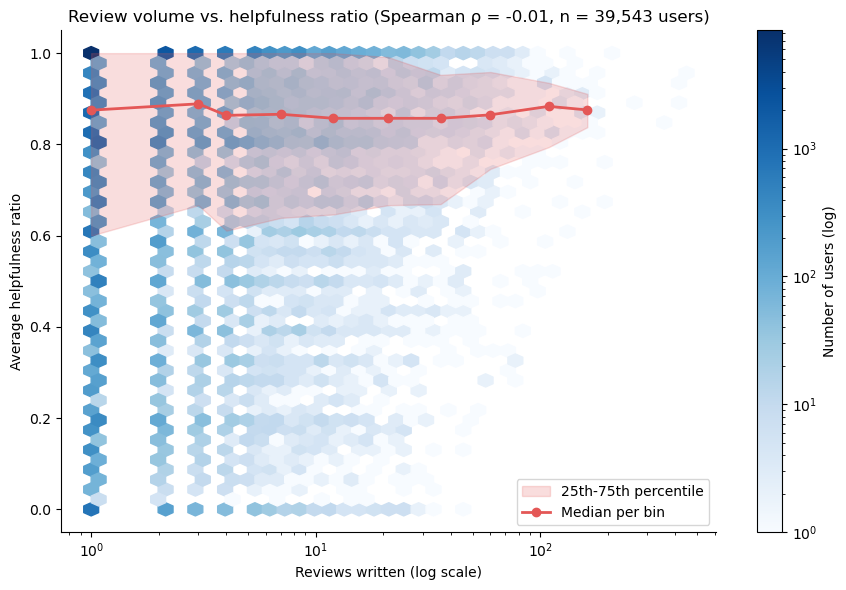

In [20]:
# More reviews posted = more helpful?
MIN_VOTED_REVIEWS = 0   # a user needs at least this many such reviews to be plotted

voted = df[df['HelpfulnessDenominator'] >= MIN_VOTES].copy()
voted['helpful_ratio'] = voted['HelpfulnessNumerator'] / voted['HelpfulnessDenominator']

plot_df = (voted.groupby('UserId')
                .agg(avg_helpful_ratio=('helpful_ratio', 'mean'),
                     n_voted=('helpful_ratio', 'count'))
                .join(user_stats.set_index('UserId')['n_reviews'])
                .reset_index())
plot_df = plot_df[plot_df['n_voted'] >= MIN_VOTED_REVIEWS]

rho = plot_df[['n_reviews', 'avg_helpful_ratio']].corr(method='spearman').iloc[0, 1]

fig, ax = plt.subplots(figsize=(9, 6))

# Density of users (hexbin handles overplotting better than a scatter)
hb = ax.hexbin(plot_df['n_reviews'], plot_df['avg_helpful_ratio'],
               xscale='log', gridsize=40, mincnt=1, cmap='Blues', bins='log')
plt.colorbar(hb, label='Number of users (log)')

# Trend: median per log-spaced bin, with a 25th-75th percentile band
bins = np.unique(np.logspace(np.log10(plot_df['n_reviews'].min()),
                             np.log10(plot_df['n_reviews'].max()), 12).round().astype(int))
plot_df = plot_df.assign(bin=pd.cut(plot_df['n_reviews'], bins=bins, include_lowest=True))
trend = plot_df.groupby('bin', observed=True).agg(
    x=('n_reviews', 'median'),
    y=('avg_helpful_ratio', 'median'),
    q25=('avg_helpful_ratio', lambda s: s.quantile(0.25)),
    q75=('avg_helpful_ratio', lambda s: s.quantile(0.75)),
    users=('UserId', 'count'),
)
trend = trend[trend['users'] >= 10]   # drop sparse bins

ax.fill_between(trend['x'], trend['q25'], trend['q75'], color='#E45756', alpha=0.2, label='25th-75th percentile')
ax.plot(trend['x'], trend['y'], color='#E45756', marker='o', linewidth=2, label='Median per bin')

ax.set_xscale('log')
ax.set_xlabel('Reviews written (log scale)')
ax.set_ylabel('Average helpfulness ratio')
ax.set_title(f'Review volume vs. helpfulness ratio (Spearman ρ = {rho:.2f}, n = {len(plot_df):,} users)')
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

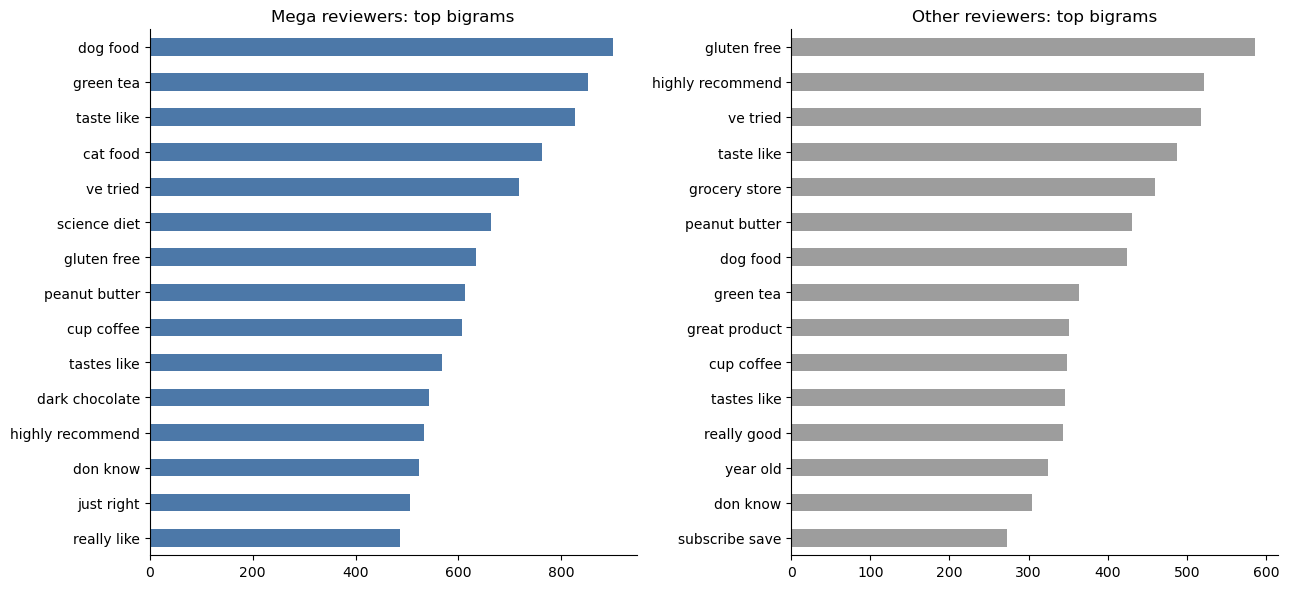

In [21]:
# Filter for relevant users 
mega_ids = user_stats.loc[user_stats['n_reviews'] >= threshold, 'UserId']
is_mega = df['UserId'].isin(mega_ids)

n = min(is_mega.sum(), (~is_mega).sum(), 20000)
mega_text = df.loc[is_mega, 'Text'].astype(str).sample(n, random_state=42).map(clean)
other_text = df.loc[~is_mega, 'Text'].astype(str).sample(n, random_state=42).map(clean)

def top_terms(texts, n=15, ngram=(2, 2)):   # use (1, 1) for single words
    cv = CountVectorizer(stop_words='english', ngram_range=ngram, min_df=5)
    X = cv.fit_transform(texts)
    counts = pd.Series(np.asarray(X.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return counts.nlargest(n).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_terms(mega_text).plot(kind='barh', ax=axes[0], color='#4C78A8', title='Mega reviewers: top bigrams')
top_terms(other_text).plot(kind='barh', ax=axes[1], color='#9D9D9D', title='Other reviewers: top bigrams')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()